# 46-923, Fall 2026: Homework #4 — Dimension Reduction

Data: WRDS *Millisecond Intraday Indicators* (`taqmsec.wrds_iid_2025`), 53 S&P 500 stocks, all trading days of 2025.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import scale
from sklearn.decomposition import PCA, KernelPCA
from sklearn import manifold

## Data

The query is cached to a `.csv` file the first time it runs, so later runs do not need a WRDS login.

In [2]:
TICKERS = ["AAPL", "MSFT", "NVDA", "ORCL", "ADBE", "CSCO", "INTC", "AMD",
           "GOOGL", "META", "NFLX", "DIS", "VZ", "T",
           "AMZN", "TSLA", "HD", "MCD", "NKE", "SBUX", "F", "CCL",
           "PG", "KO", "PEP", "WMT", "COST",
           "JNJ", "UNH", "PFE", "MRK", "ABBV",
           "JPM", "BAC", "GS", "MS", "V", "HBAN",
           "XOM", "CVX", "COP", "KMI",
           "CAT", "BA", "HON", "UPS", "GE",
           "NEE", "DUK", "LIN", "NEM", "FCX", "PLD", "AMT"]

CACHE = "iid_2025_sample.csv"

if os.path.exists(CACHE):
    df = pd.read_csv(CACHE, parse_dates=["date"])
else:
    import wrds
    db = wrds.Connection(wrds_username="ryez")
    tick_sql = ", ".join(f"'{t}'" for t in TICKERS)
    sql_query = f"""
        SELECT *
        FROM taqmsec.wrds_iid_2025
        WHERE sym_root IN ({tick_sql})
            AND (sym_suffix IS NULL OR sym_suffix = '')
    """
    df = db.raw_sql(sql_query, date_cols=["date"])
    db.close()
    df.to_csv(CACHE, index=False)

print(f"{df.shape[0]} stock-days, {df.shape[1]} columns, {df['sym_root'].nunique()} stocks")

13250 stock-days, 209 columns, 53 stocks


## Choice of Variables

We use 15 variables that all measure **how much trading a stock had on a given day**, broken down by type of trade:

In [3]:
V = [
    # all trades: count, dollar volume
    "total_n_trades_m", "total_dollar_m",
    # odd lots (< 100 shares)
    "n_oddlot_trade", "oddlot_dollar",
    # intermarket sweep orders
    "n_iso_trade", "iso_dollar",
    # retail trades
    "total_trade_retail", "total_dv_retail",
    # institutional trades >= $20K and >= $50K
    "total_trade_inst20k", "total_dv_inst20k",
    "total_trade_inst50k", "total_dv_inst50k",
    # trades priced outside the NBBO
    "n_outside_nbbo_trade",
    # pre-market / after-hours dollar volume
    "total_dollar_b", "total_dollar_a",
]

These are good candidates for dimension reduction for two reasons.

First, the odd-lot, ISO, retail and institutional trades are all **subsets of the same day's trades**, so they should rise and fall together.

Second, counts and dollar volumes are tied together by the identity
$$
\text{dollar volume} = \text{number of trades} \times \text{shares per trade} \times \text{price}.
$$
After a log transform this becomes a sum:
$$
\log(\text{dollar volume}) = \log(\text{trades}) + \log(\text{shares per trade}) + \log(\text{price}).
$$
So we expect a few underlying quantities (activity, trade size, price) to explain most of the 15 variables.

The relationships may also be **nonlinear**. "Odd lot" and "\$50K trade" are fixed thresholds, while share prices range from about \$11 to over \$1,000, so the mix of trade types changes with the price level.

## Preparation

All 15 variables are positive and strongly right-skewed, so we take $\log_{10}$ of each. Because they are in different units (counts and dollars), each logged variable is then standardized (Part 17, p. 25).

Kernel PCA, ISOMAP and t-SNE work with $n \times n$ matrices, so we run all four methods on a random subsample of **60 days per stock** ($53 \times 60 = 3{,}180$ rows). That is large enough to show structure and small enough that each method runs in seconds.

In [4]:
logX = np.log10(df[V])
df["log10_price"] = np.log10(df["sym_root"].map(df.groupby("sym_root")["vw_price_m"].median()))

sub_idx = df.groupby("sym_root", group_keys=False).sample(60, random_state=0).index
sub = df.loc[sub_idx].reset_index(drop=True)
Z = scale(logX.loc[sub_idx])
print(Z.shape)

(3180, 15)


## PCA

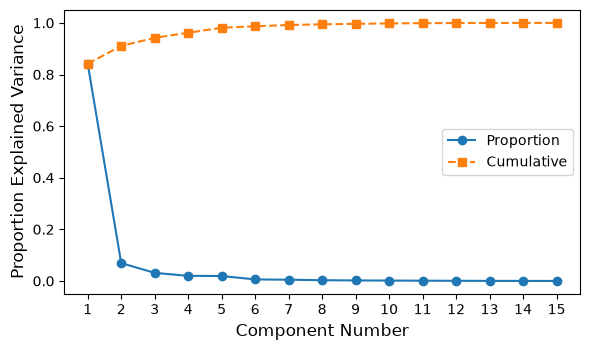

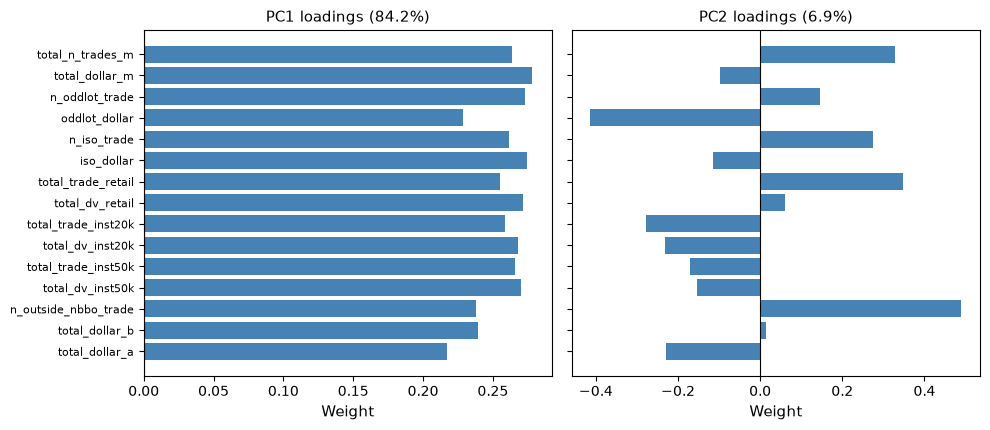

In [5]:
pca = PCA().fit(Z)
Y_pca = pca.transform(Z)[:, :2]

fig, ax = plt.subplots(figsize=[6, 3.6])
k = np.arange(1, len(V) + 1)
ax.plot(k, pca.explained_variance_ratio_, marker="o", label="Proportion")
ax.plot(k, pca.explained_variance_ratio_.cumsum(), marker="s", ls="--", label="Cumulative")
ax.set_xlabel("Component Number", size=12)
ax.set_ylabel("Proportion Explained Variance", size=12)
ax.set_xticks(k)
ax.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=[10, 4.4], sharey=True)
for j, ax in enumerate(axes):
    ax.barh(range(len(V)), pca.components_[j], color="steelblue")
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlabel("Weight", size=11)
    ax.set_title(f"PC{j+1} loadings ({pca.explained_variance_ratio_[j]:.1%})", size=11)
axes[0].set_yticks(range(len(V)))
axes[0].set_yticklabels(V, size=8)
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

The first two components explain about 84% and 7% of the variance, **91% together**.

* **PC1** weights all 15 variables about equally, so it is an overall **trading-activity / size** factor.
* **PC2** contrasts trade *counts* (positive) with *dollar* amounts and institutional trades (negative). By the identity above, that difference is $\log(\text{shares per trade}) + \log(\text{price})$. PC2 is therefore essentially (minus) the **average dollar size of a trade**, which is driven mainly by the share price.

## Kernel PCA, ISOMAP and t-SNE

The three nonlinear methods are set up as follows.

* **Kernel PCA** uses the RBF kernel (Part 18, pp. 3–8). We set $\gamma = 1/\text{median}\,\|{\bf x}_i - {\bf x}_j\|^2$, so that a typical pair of points has similarity $e^{-1}$.
* **ISOMAP** uses $K = 10$ neighbors (Part 18, pp. 16–21). With this $K$ the neighbor graph is connected.
* **t-SNE** uses the default perplexity of 30 (Part 18, pp. 24–29).

All four 2-D representations are plotted together, with each point colored by its stock's median share price. Price was not used to fit any of them.

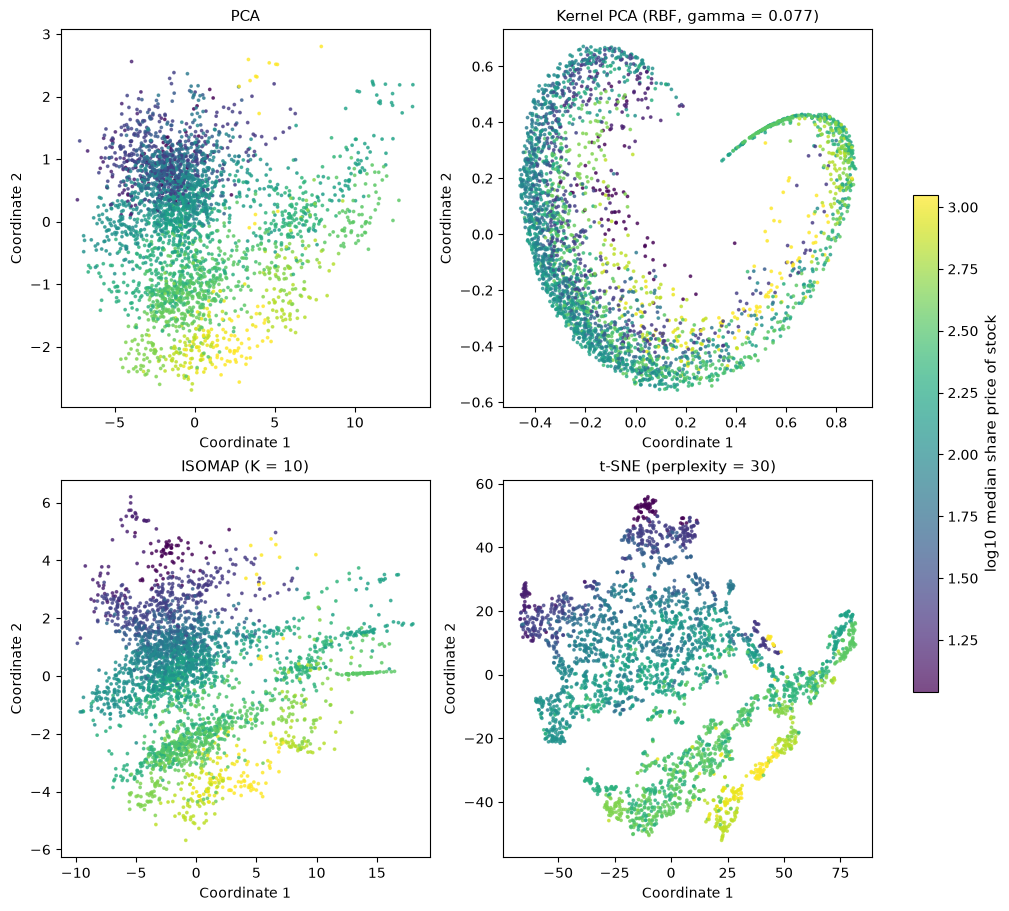

In [6]:
sq_d = ((Z[:, None, :] - Z[None, :, :]) ** 2).sum(-1)
gamma = 1 / np.median(sq_d[np.triu_indices_from(sq_d, k=1)])

emb = {
    "PCA": Y_pca,
    f"Kernel PCA (RBF, gamma = {gamma:.3f})": KernelPCA(n_components=2, kernel="rbf", gamma=gamma).fit_transform(Z),
    "ISOMAP (K = 10)": manifold.Isomap(n_neighbors=10, n_components=2).fit_transform(Z),
    "t-SNE (perplexity = 30)": manifold.TSNE(n_components=2, random_state=0).fit_transform(Z),
}

fig, axes = plt.subplots(2, 2, figsize=[10, 9], layout="constrained")
for ax, (name, Y) in zip(axes.flatten(), emb.items()):
    sc = ax.scatter(Y[:, 0], Y[:, 1], c=sub["log10_price"], cmap="viridis", s=3, alpha=0.7)
    ax.set_title(name, size=11)
    ax.set_xlabel("Coordinate 1", size=10)
    ax.set_ylabel("Coordinate 2", size=10)
cbar = fig.colorbar(sc, ax=axes, shrink=0.6)
cbar.set_label("log10 median share price of stock", size=11)
plt.show()

## Interpretation

* **PCA and ISOMAP** give similar pictures. The first coordinate is stock size/activity and the second sorts the points by share price. ISOMAP's price ordering is a little cleaner. Each stock appears as a small elongated cloud: its day-to-day variation, which runs along the activity direction.
* **Kernel PCA** bends what is essentially a straight size gradient into a curve (the "horseshoe" effect), and the second coordinate adds little beyond the first. The structure here is already close to linear in log space, so the RBF kernel does not help.
* **t-SNE** breaks the data into islands, and each island is mostly a single stock. It also keeps the price ordering across islands. It is the best at preserving local neighborhoods, but distances between islands, and the axes themselves, have no meaning.

**Conclusion.** The 15 variables compress well. Two dimensions, overall activity and average trade size (share price), keep about 91% of the variance. Because the relationships are close to linear after taking logs, plain PCA already captures the global structure. The nonlinear methods mainly add detail at the local level, most clearly t-SNE's separation of individual stocks.